# 07 · Representación TF-IDF, similitud y modelos de regresión

La bolsa de palabras trata a todas las palabras por igual: una palabra tan común como *the* pesa lo mismo que un
término propio del texto. TF-IDF corrige eso, dando más peso a las palabras que distinguen a un resumen y menos a las
que aparecen en casi todos. Además, permite medir qué tan parecido es cada resumen a su texto fuente.

Aquí probamos si estas mejoras ayudan a generalizar a prompts nuevos. Todos los modelos léxicos, incluida BoW, se
evalúan con la misma validación por prompt y con una búsqueda de hiperparámetros agrupada por prompt.

## 1. Carga de datos y configuración

Se utilizaron las copias limpias del conjunto de entrenamiento. El texto fuente se incorporó mediante prompt_id, con una relación de muchos resúmenes a un único texto fuente.

In [1]:
from pathlib import Path
from time import perf_counter
import json
import platform
import sys
import os
import tempfile

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from IPython import get_ipython
from scipy import sparse
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge, SGDRegressor
from sklearn.metrics import make_scorer
from sklearn.model_selection import GridSearchCV, GroupKFold, LeaveOneGroupOut, train_test_split
from sklearn.multioutput import MultiOutputRegressor
from sklearn.pipeline import Pipeline

PROJECT_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
                    if (path / "src").is_dir() and (path / "notebooks").is_dir())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.bow import regression_metrics, coefficient_table
from src.data_loader import load_csv_files
from src.tfidf import (SummaryTfidfFeatures, SummaryBowFeatures, build_tfidf_vectorizer,
                       paired_cosine_similarity, predict_scores, transform_prompt_texts)
from src.tokenization import tokenize_text
get_ipython().run_line_magic("matplotlib", "inline")

TABLES_DIR = PROJECT_ROOT / "outputs/tables"
FIGURES_DIR = PROJECT_ROOT / "outputs/figures"
PROCESSED_DIR = PROJECT_ROOT / "data/processed"
for directory in [TABLES_DIR, FIGURES_DIR, PROCESSED_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
datasets = load_csv_files(PROJECT_ROOT / "data/interim",
                         ["summaries_train_clean.csv", "prompts_train_clean.csv"])
summaries = datasets["summaries_train_clean"]
prompts = datasets["prompts_train_clean"]
data = summaries.merge(prompts[["prompt_id", "prompt_title", "prompt_text"]],
                       on="prompt_id", how="left", validate="many_to_one", sort=False)
TARGETS = ["content", "wording"]
X = data[["text", "prompt_text"]]
y = data[TARGETS].to_numpy()
groups = data["prompt_id"].to_numpy()
assert len(data) == len(summaries) and data["student_id"].is_unique
assert data["prompt_text"].notna().all() and np.isfinite(y).all()
assert data["student_id"].tolist() == summaries["student_id"].tolist()
plt.rcParams.update({"figure.figsize": [10, 5], "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})
COLORS = {"content": "#3978a8", "wording": "#c78145"}
display(pd.DataFrame({"resúmenes": [len(data)], "prompts": [data.prompt_id.nunique()],
                      "objetivos": [", ".join(TARGETS)]}))

,resúmenes,prompts,objetivos
0,7165,4,"content, wording"


## 2. Construcción y diagnóstico de la matriz TF-IDF

Se utilizó la ponderación de términos descrita por Salton y Buckley (1988). Se calculó la frecuencia con transformación logarítmica y se aplicó IDF suavizado. Se normalizó cada fila con norma L2. El IDF utilizado fue log((1 + número de documentos) / (1 + frecuencia documental)) + 1. La frecuencia transformada fue 1 + log(conteo) para los términos presentes.

La matriz de esta sección describe el conjunto completo y no se utiliza para entrenar los modelos evaluados. En las secciones de modelado se vuelve a ajustar el vectorizador dentro de cada partición.

,documentos,vocabulario,valores_no_cero,densidad,dispersion,min_df,max_df,ngram_range,sublinear_tf,smooth_idf,norm,max_features
0,7165,12469,350262,0.003921,0.996079,1,0.98,"1,1",True,True,l2,sin límite


,token,tfidf
8,experimentto,0.26730
20,leader,0.26554
28,radical,0.25550
29,reacted,0.24713
7,experement,0.22696
22,new,0.22395
26,popularity,0.22353
5,blindly,0.21282
6,eachother,0.19751
12,gained,0.19155


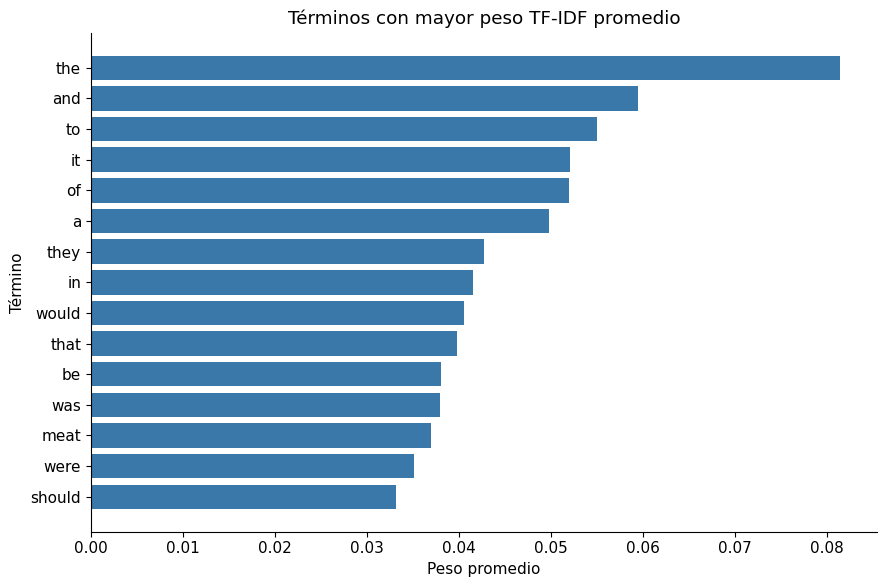

La matriz contiene 12,469 términos y 99.61 % de ceros.


In [2]:
descriptive_vectorizer = build_tfidf_vectorizer(min_df=1, ngram_range=(1, 1))
matrix = descriptive_vectorizer.fit_transform(data["text"])
names = descriptive_vectorizer.get_feature_names_out()
assert sparse.isspmatrix_csr(matrix) and matrix.shape[0] == len(data)
assert np.isfinite(matrix.data).all() and matrix.data.min() > 0
row_norms = np.sqrt(np.asarray(matrix.power(2).sum(axis=1)).ravel())
assert np.allclose(row_norms[row_norms > 0], 1)
matrix_summary = pd.DataFrame([{
    "documentos": matrix.shape[0], "vocabulario": matrix.shape[1],
    "valores_no_cero": matrix.nnz, "densidad": matrix.nnz / np.prod(matrix.shape),
    "dispersion": 1 - matrix.nnz / np.prod(matrix.shape),
    "min_df": 1, "max_df": 0.98, "ngram_range": "1,1", "sublinear_tf": True,
    "smooth_idf": True, "norm": "l2", "max_features": "sin límite",
}])
display(matrix_summary)
matrix_summary.to_csv(TABLES_DIR / "07_tfidf_matrix_summary.csv", index=False)
sparse.save_npz(PROCESSED_DIR / "07_tfidf_descriptive_matrix.npz", matrix)
term_weights = pd.DataFrame({"token": names, "idf": descriptive_vectorizer.idf_,
    "peso_promedio": np.asarray(matrix.mean(axis=0)).ravel(),
    "documentos": np.asarray((matrix > 0).sum(axis=0)).ravel()})
term_weights = term_weights.sort_values("peso_promedio", ascending=False).reset_index(drop=True)
term_weights.to_csv(TABLES_DIR / "07_tfidf_term_weights.csv", index=False)
example = matrix.getrow(0)
example_terms = pd.DataFrame({"token": names[example.indices], "tfidf": example.data})
example_terms = example_terms.sort_values("tfidf", ascending=False).head(15)
display(example_terms.round(5))
example_terms.to_csv(TABLES_DIR / "07_tfidf_example_document.csv", index=False)
top_terms = term_weights.head(15).sort_values("peso_promedio")
fig, ax = plt.subplots(figsize=[9, 6])
ax.barh(top_terms.token, top_terms.peso_promedio, color=COLORS["content"])
ax.set(title="Términos con mayor peso TF-IDF promedio", xlabel="Peso promedio", ylabel="Término")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "07_tfidf_top_terms.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"La matriz contiene {matrix.shape[1]:,} términos y {100 * matrix_summary.dispersion.iloc[0]:.2f} % de ceros.")

### Interpretación de la representación

Cada fila corresponde a un resumen y cada columna a un término. Los valores representan pesos y no conteos. La matriz dispersa permite almacenar solo las celdas activas. Un término frecuente en un resumen puede conservar un peso alto aunque sea común en el corpus; TF-IDF reduce su peso relativo, pero no lo elimina.

El promedio global puede estar dominado por el tema y la cantidad de resúmenes de cada prompt. Los términos de mayor peso no deben interpretarse como indicadores generales de calidad.

## 3. Sensibilidad de la configuración

Se comparó el número de términos retenidos al cambiar min_df y al incluir bigramas. Este diagnóstico describe el tamaño de las representaciones. La selección de parámetros predictivos se realizó después con datos de entrenamiento.

,ngram_range,min_df,vocabulario,valores_no_cero,dispersion
0,"(1, 1)",1,12469,350262,0.99608
1,"(1, 1)",3,4102,340461,0.98842
2,"(1, 1)",5,3007,336739,0.98437
3,"(1, 1)",10,2095,330767,0.97796
4,"(1, 2)",1,107731,844267,0.99891
5,"(1, 2)",3,23023,747071,0.99547
6,"(1, 2)",5,14544,718475,0.99311
7,"(1, 2)",10,8399,678730,0.98872


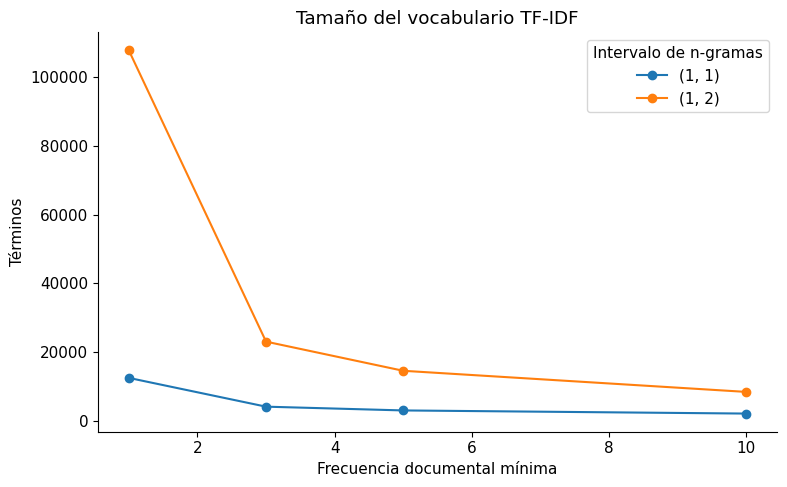

In [3]:
diagnostic_rows = []
for ngram_range in [(1, 1), (1, 2)]:
    for min_df in [1, 3, 5, 10]:
        vectorizer = build_tfidf_vectorizer(min_df=min_df, ngram_range=ngram_range)
        candidate = vectorizer.fit_transform(data["text"])
        diagnostic_rows.append({"ngram_range": str(ngram_range), "min_df": min_df,
            "vocabulario": candidate.shape[1], "valores_no_cero": candidate.nnz,
            "dispersion": 1 - candidate.nnz / np.prod(candidate.shape)})
vocabulary_diagnostic = pd.DataFrame(diagnostic_rows)
display(vocabulary_diagnostic.round(5))
vocabulary_diagnostic.to_csv(TABLES_DIR / "07_tfidf_vocabulary_diagnostic.csv", index=False)
fig, ax = plt.subplots(figsize=[8, 5])
for label, group in vocabulary_diagnostic.groupby("ngram_range"):
    ax.plot(group.min_df, group.vocabulario, marker="o", label=label)
ax.set(title="Tamaño del vocabulario TF-IDF", xlabel="Frecuencia documental mínima", ylabel="Términos")
ax.legend(title="Intervalo de n-gramas")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "07_tfidf_vocabulary_size.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Similitud entre el resumen y su texto fuente

Se transformó el texto fuente con el mismo vocabulario e IDF de la matriz descriptiva. Se calculó el coseno de cada resumen con su propia fuente, sin comparar todas las parejas posibles. Se asignó similitud cero si alguna representación no contenía términos conocidos.

Esta similitud mide coincidencia léxica ponderada. En la evaluación predictiva se calculó con el vectorizador ajustado únicamente en el entrenamiento.

,count,mean,std,min,25%,50%,75%,max
tfidf_prompt_similarity,7165.0,0.20891,0.09303,0.03008,0.14211,0.19241,0.25976,0.85816


,token_count,content,wording
tfidf_prompt_similarity,0.61522,0.49662,0.12216


,prompt_id,prompt_title,filas,similitud_media,similitud_mediana,spearman_token_count,spearman_content,spearman_wording
0,39c16e,On Tragedy,2057,0.18967,0.17837,0.41161,0.33322,0.06406
1,3b9047,Egyptian Social Structure,2009,0.22649,0.21173,0.62556,0.57297,0.14420
2,814d6b,The Third Wave,1103,0.19436,0.17159,0.69856,0.63701,0.38835
3,ebad26,Excerpt from The Jungle,1996,0.21910,0.20995,0.71775,0.49642,0.10274


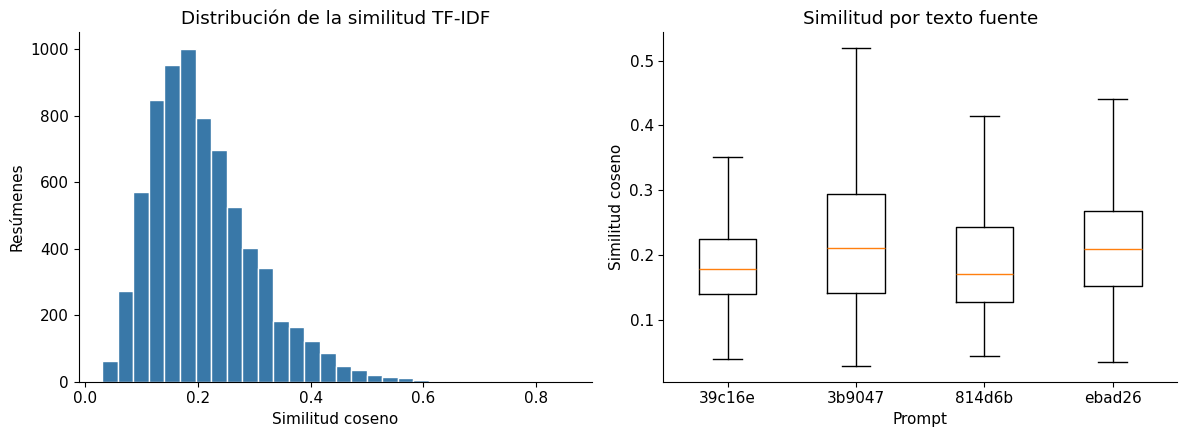

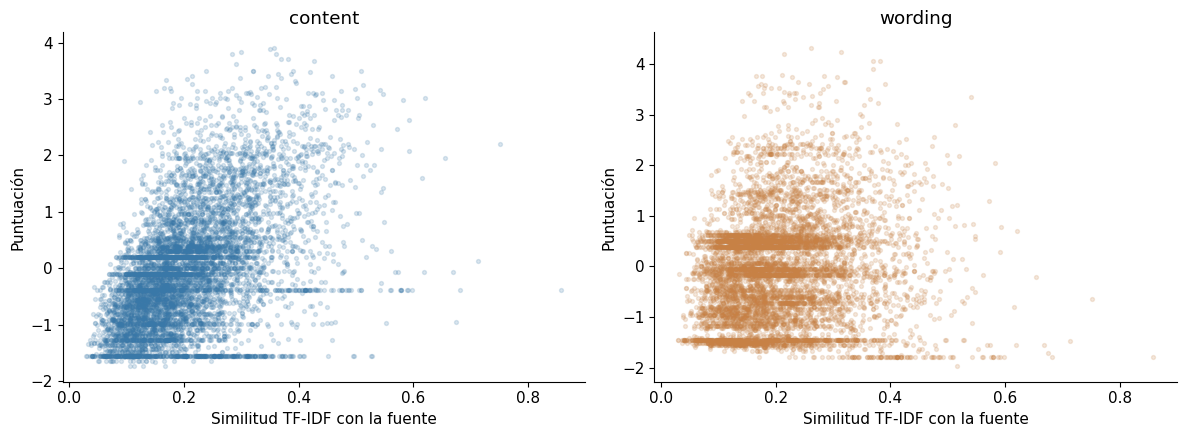

In [4]:
source_matrix = transform_prompt_texts(descriptive_vectorizer, data["prompt_text"])
similarity = paired_cosine_similarity(matrix, source_matrix)
similarity_frame = data[["student_id", "prompt_id", "prompt_title", *TARGETS]].copy()
similarity_frame["tfidf_prompt_similarity"] = similarity
similarity_frame["token_count"] = data["text"].map(tokenize_text).str.len()
similarity_description = similarity_frame["tfidf_prompt_similarity"].describe().to_frame().T
correlation_columns = ["tfidf_prompt_similarity", "token_count", *TARGETS]
similarity_correlations = similarity_frame[correlation_columns].corr(method="spearman").loc[
    ["tfidf_prompt_similarity"], ["token_count", *TARGETS]]
prompt_rows = []
for prompt_id, group in similarity_frame.groupby("prompt_id"):
    correlations = group[correlation_columns].corr(method="spearman")
    prompt_rows.append({"prompt_id": prompt_id, "prompt_title": group.prompt_title.iloc[0],
        "filas": len(group), "similitud_media": group.tfidf_prompt_similarity.mean(),
        "similitud_mediana": group.tfidf_prompt_similarity.median(),
        **{f"spearman_{target}": correlations.loc["tfidf_prompt_similarity", target]
           for target in ["token_count", *TARGETS]}})
similarity_by_prompt = pd.DataFrame(prompt_rows)
display(similarity_description.round(5))
display(similarity_correlations.round(5))
display(similarity_by_prompt.round(5))
similarity_frame.to_csv(TABLES_DIR / "07_tfidf_similarity_by_summary.csv", index=False)
similarity_description.to_csv(TABLES_DIR / "07_tfidf_similarity_descriptive.csv", index_label="variable")
similarity_correlations.to_csv(TABLES_DIR / "07_tfidf_similarity_correlations.csv", index_label="variable")
similarity_by_prompt.to_csv(TABLES_DIR / "07_tfidf_similarity_by_prompt.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=[12, 4.5])
axes[0].hist(similarity, bins=30, color=COLORS["content"], edgecolor="white")
axes[0].set(title="Distribución de la similitud TF-IDF", xlabel="Similitud coseno", ylabel="Resúmenes")
prompt_order = similarity_by_prompt.prompt_id.tolist()
axes[1].boxplot([similarity_frame.loc[similarity_frame.prompt_id.eq(p), "tfidf_prompt_similarity"]
                 for p in prompt_order], tick_labels=prompt_order, showfliers=False)
axes[1].set(title="Similitud por texto fuente", xlabel="Prompt", ylabel="Similitud coseno")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "07_tfidf_similarity_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
fig, axes = plt.subplots(1, 2, figsize=[12, 4.5])
for ax, target in zip(axes, TARGETS):
    ax.scatter(similarity, data[target], s=8, alpha=0.18, color=COLORS[target])
    ax.set(title=target, xlabel="Similitud TF-IDF con la fuente", ylabel="Puntuación")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "07_tfidf_similarity_vs_targets.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretación de los resultados de similitud

La correlación de Spearman fue 0.4966 con content y 0.1222 con wording. La relación con la cantidad de tokens fue 0.6152. Se observó una asociación mayor con la cobertura de contenido que con wording. La relación con la longitud indica que la similitud debe interpretarse junto con la extensión y el prompt. Estas asociaciones no permiten afirmar que aumentar la coincidencia con el texto fuente mejore la puntuación.

### Interpretación de la similitud

Se reportaron las correlaciones globales y por prompt porque la mezcla de temas puede cambiar la relación observada. También se incluyó la longitud para reconocer posibles asociaciones con la extensión del resumen. Una correlación no demuestra que aumentar la coincidencia con la fuente mejore la puntuación. El uso de vocabulario propio del tema y la copia de fragmentos pueden producir similitudes altas por razones distintas.

## 5. Particiones, modelos y ajuste de parámetros

Se conservó una prueba de 20 % estratificada por prompt_id y una validación interna de 20 % del resto, con semilla 42. Esta partición coincide con la utilizada en el análisis de BoW y mide el desempeño sobre nuevos resúmenes de temas conocidos.

Se realizó además una validación externa Leave-One-Prompt-Out. En cada partición se entrenó con tres textos fuente y se evaluó con el cuarto. Los parámetros se seleccionaron con GroupKFold dentro de los tres prompts de entrenamiento. De esta forma, el prompt externo no se utilizó para seleccionar parámetros, vocabulario o IDF.

Se compararon una predicción por la media, BoW binario con Ridge, TF-IDF de unigramas con Ridge, TF-IDF de unigramas y bigramas con Ridge, TF-IDF con SGD y TF-IDF con similitud y Ridge. Ridge controla coeficientes grandes mediante regularización. SGD permite aproximar una regresión regularizada con actualizaciones iterativas. Se aplicó parada temprana en SGD con 10 % de los datos disponibles en cada ajuste; esta separación se realizó dentro del entrenamiento. Se usaron modelos de regresión porque content y wording son variables continuas.

Se eligió la configuración con menor MCRMSE de validación. Se reportaron RMSE, MAE y R2 por objetivo. MCRMSE es el promedio de los dos RMSE. Los tiempos de búsqueda, entrenamiento final y predicción se midieron por separado.

In [5]:
indices = np.arange(len(data))
train_indices, test_indices = train_test_split(indices, test_size=0.20, random_state=42, stratify=groups)
inner_train, validation_indices = train_test_split(train_indices, test_size=0.20,
                                                   random_state=42, stratify=groups[train_indices])
assert set(train_indices).isdisjoint(test_indices)
assert set(inner_train).isdisjoint(validation_indices)
split_frame = data[["student_id", "prompt_id"]].copy()
split_frame["particion"] = "prueba"
split_frame.loc[inner_train, "particion"] = "entrenamiento"
split_frame.loc[validation_indices, "particion"] = "validacion"
split_counts = split_frame.particion.value_counts().rename_axis("particion").to_frame("filas")
display(split_counts)
split_frame.to_csv(TABLES_DIR / "07_tfidf_split_assignments.csv", index=False)
split_counts.to_csv(TABLES_DIR / "07_tfidf_split_counts.csv")

def negative_mcrmse(observed, predicted):
    return -regression_metrics(observed, predicted)["mcrmse"]

SCORER = make_scorer(negative_mcrmse, greater_is_better=True)
cache_directory = tempfile.TemporaryDirectory(prefix="tfidf_")
FEATURE_CACHE = joblib.Memory(os.environ.get("COMMONLIT_TFIDF_CACHE_DIR", cache_directory.name), verbose=0)
MODEL_ORDER = ["Dummy media", "BoW binario + Ridge", "TF-IDF unigramas + Ridge",
               "TF-IDF unigramas y bigramas + Ridge", "TF-IDF + SGD",
               "TF-IDF y similitud + Ridge"]

def model_spec(name):
    if name == "Dummy media":
        return Pipeline([("model", DummyRegressor(strategy="mean"))]), {}
    if name == "BoW binario + Ridge":
        features = SummaryBowFeatures(binary=True)
        model = Ridge(solver="lsqr")
        grid = {"features__min_df": [1, 3], "model__alpha": [1.0, 10.0, 100.0]}
    else:
        ngrams = (1, 1) if name == "TF-IDF unigramas + Ridge" else (1, 2)
        features = SummaryTfidfFeatures(ngram_range=ngrams,
                                        include_similarity=name == "TF-IDF y similitud + Ridge")
        if name == "TF-IDF + SGD":
            model = MultiOutputRegressor(SGDRegressor(max_iter=1000, tol=1e-3, random_state=42,
                early_stopping=True, validation_fraction=0.10, n_iter_no_change=5, average=True))
            grid = {"features__min_df": [1, 3], "model__estimator__alpha": [1e-5, 1e-4, 1e-3]}
        else:
            model = Ridge(solver="lsqr")
            grid = {"features__min_df": [1, 3], "model__alpha": [0.1, 1.0, 10.0]}
    return Pipeline([("features", features), ("model", model)], memory=FEATURE_CACHE), grid

search_rows = []
parameter_rows = []

def select_model(name, train_idx, splits, protocol, fold):
    pipeline, grid = model_spec(name)
    if not grid:
        return pipeline, 0.0
    search = GridSearchCV(pipeline, grid, scoring=SCORER, cv=splits, refit=False,
                          n_jobs=1, error_score="raise", return_train_score=False)
    start = perf_counter()
    search.fit(X.iloc[train_idx], y[train_idx])
    seconds = perf_counter() - start
    for position, params in enumerate(search.cv_results_["params"]):
        search_rows.append({"protocolo": protocol, "fold": fold, "modelo": name,
            "parametros": json.dumps(params, sort_keys=True),
            "mcrmse_validacion_promedio": -search.cv_results_["mean_test_score"][position],
            "desviacion_validacion": search.cv_results_["std_test_score"][position],
            "seleccionado": position == search.best_index_})
    parameter_rows.append({"protocolo": protocol, "fold": fold, "modelo": name,
        "parametros": json.dumps(search.best_params_, sort_keys=True),
        "mcrmse_validacion": -search.best_score_, "tiempo_busqueda_s": seconds})
    return pipeline.set_params(**search.best_params_), seconds

def fit_and_measure(model, train_idx, valid_idx):
    model.set_params(memory=None)
    start = perf_counter()
    model.fit(X.iloc[train_idx], y[train_idx])
    fit_seconds = perf_counter() - start
    start = perf_counter()
    prediction = model.predict(X.iloc[valid_idx])
    prediction_seconds = perf_counter() - start
    return prediction, fit_seconds, prediction_seconds

,filas
particion,
entrenamiento,4585
prueba,1433
validacion,1147


## 6. Resultados sobre prompts conocidos

La prueba final no participó en la selección de parámetros. Después del ajuste se entrenó cada configuración con las 5,732 filas disponibles fuera de la prueba y se evaluó con 1,433 filas.

In [6]:
train_position = {int(row): position for position, row in enumerate(train_indices)}
holdout_split = [(np.array([train_position[int(i)] for i in inner_train]),
                  np.array([train_position[int(i)] for i in validation_indices]))]
holdout_rows, holdout_predictions, holdout_models = [], {}, {}
for name in MODEL_ORDER:
    model, search_seconds = select_model(name, train_indices, holdout_split, "prompts_conocidos", "holdout")
    prediction, fit_seconds, prediction_seconds = fit_and_measure(model, train_indices, test_indices)
    holdout_rows.append({"modelo": name, "tiempo_busqueda_s": search_seconds,
        "tiempo_entrenamiento_s": fit_seconds, "tiempo_prediccion_s": prediction_seconds,
        "vocabulario": len(model.named_steps["features"].vectorizer_.vocabulary_)
                        if "features" in model.named_steps else 0,
        **regression_metrics(y[test_indices], prediction)})
    holdout_predictions[name] = prediction
    holdout_models[name] = model
    print(name, "MCRMSE", round(holdout_rows[-1]["mcrmse"], 5), flush=True)
holdout_results = pd.DataFrame(holdout_rows).sort_values("mcrmse").reset_index(drop=True)
display(holdout_results.round(5))
holdout_results.to_csv(TABLES_DIR / "07_tfidf_holdout_results.csv", index=False)

Dummy media MCRMSE 1.04924


BoW binario + Ridge MCRMSE 0.59067


TF-IDF unigramas + Ridge MCRMSE 0.63673


TF-IDF unigramas y bigramas + Ridge MCRMSE 0.61254


TF-IDF + SGD MCRMSE 0.92067


TF-IDF y similitud + Ridge MCRMSE 0.61303


,modelo,tiempo_busqueda_s,tiempo_entrenamiento_s,tiempo_prediccion_s,vocabulario,rmse_content,mae_content,r2_content,rmse_wording,mae_wording,r2_wording,mcrmse
0,BoW binario + Ridge,5.77493,2.48335,0.21738,11031,0.50817,0.38980,0.76473,0.67316,0.53242,0.58942,0.59067
1,TF-IDF unigramas y bigramas + Ridge,9.54642,4.45398,0.48730,19675,0.54200,0.42181,0.73237,0.68307,0.53257,0.57724,0.61254
2,TF-IDF y similitud + Ridge,9.08530,4.96784,0.65668,19675,0.54306,0.41864,0.73132,0.68300,0.53255,0.57732,0.61303
3,TF-IDF unigramas + Ridge,4.48689,2.22565,0.27344,3676,0.56264,0.43424,0.71159,0.71081,0.55354,0.54220,0.63673
4,TF-IDF + SGD,20.71268,7.64717,0.46062,19675,0.90718,0.71376,0.25023,0.93416,0.73558,0.20932,0.92067
5,Dummy media,0.00000,0.00522,0.00101,0,1.04773,0.81972,-0.00009,1.05076,0.83566,-0.00039,1.04924


### Interpretación de los modelos con prompts conocidos

BoW binario con Ridge obtuvo MCRMSE de 0.59067. La combinación TF-IDF de unigramas y bigramas con Ridge obtuvo 0.61254, frente a 0.63673 de los unigramas. Los bigramas redujeron el error de TF-IDF en esta prueba, aunque BoW conservó el menor error global. SGD quedó por detrás de Ridge con los parámetros evaluados. La comparación corresponde a nuevos resúmenes de textos fuente que sí estuvieron representados en el entrenamiento.

## 7. Resultados sobre prompts no vistos

Cada resumen recibió una predicción de un modelo que no utilizó ejemplos de su texto fuente. Se calcularon las métricas globales a partir de todas las predicciones externas. La selección interna utilizó el promedio del MCRMSE de los tres prompts internos, con el mismo peso para cada uno.

In [7]:
grouped_predictions = {name: np.full_like(y, np.nan) for name in MODEL_ORDER}
grouped_time = {name: {"tiempo_busqueda_s": 0.0, "tiempo_entrenamiento_s": 0.0,
                      "tiempo_prediccion_s": 0.0} for name in MODEL_ORDER}
fold_rows = []
external_membership = np.zeros(len(data), dtype=int)
for fold, (outer_train, outer_test) in enumerate(LeaveOneGroupOut().split(X, y, groups), start=1):
    assert set(groups[outer_train]).isdisjoint(groups[outer_test])
    external_membership[outer_test] += 1
    inner_splits = list(GroupKFold(n_splits=3).split(X.iloc[outer_train], y[outer_train], groups[outer_train]))
    for fit_idx, valid_idx in inner_splits:
        assert set(groups[outer_train[fit_idx]]).isdisjoint(groups[outer_train[valid_idx]])
    for name in MODEL_ORDER:
        model, search_seconds = select_model(name, outer_train, inner_splits, "prompt_no_visto", fold)
        prediction, fit_seconds, prediction_seconds = fit_and_measure(model, outer_train, outer_test)
        grouped_predictions[name][outer_test] = prediction
        grouped_time[name]["tiempo_busqueda_s"] += search_seconds
        grouped_time[name]["tiempo_entrenamiento_s"] += fit_seconds
        grouped_time[name]["tiempo_prediccion_s"] += prediction_seconds
        fold_rows.append({"fold": fold, "modelo": name, "prompt_id": groups[outer_test][0],
            "prompt_title": data.iloc[outer_test].prompt_title.iloc[0], "filas": len(outer_test),
            "tiempo_busqueda_s": search_seconds, "tiempo_entrenamiento_s": fit_seconds,
            "tiempo_prediccion_s": prediction_seconds,
            **regression_metrics(y[outer_test], prediction)})
        print("Fold", fold, name, "MCRMSE", round(fold_rows[-1]["mcrmse"], 5), flush=True)
assert np.all(external_membership == 1)
fold_results = pd.DataFrame(fold_rows)
grouped_results = pd.DataFrame([{"modelo": name, **grouped_time[name],
    **regression_metrics(y, predictions)} for name, predictions in grouped_predictions.items()])
grouped_results["desviacion_mcrmse_entre_prompts"] = grouped_results.modelo.map(
    fold_results.groupby("modelo").mcrmse.std())
grouped_results = grouped_results.sort_values("mcrmse").reset_index(drop=True)
display(grouped_results.round(5))
display(fold_results.pivot(index="modelo", columns="prompt_id", values="mcrmse").round(5))
grouped_results.to_csv(TABLES_DIR / "07_tfidf_grouped_results.csv", index=False)
fold_results.to_csv(TABLES_DIR / "07_tfidf_grouped_folds.csv", index=False)
pd.DataFrame(search_rows).to_csv(TABLES_DIR / "07_tfidf_parameter_search.csv", index=False)
pd.DataFrame(parameter_rows).to_csv(TABLES_DIR / "07_tfidf_selected_parameters.csv", index=False)
prediction_frames = []
for name, prediction in grouped_predictions.items():
    rows = data[["student_id", "prompt_id", *TARGETS]].copy()
    rows["modelo"] = name
    for j, target in enumerate(TARGETS):
        rows[f"pred_{target}"] = prediction[:, j]
        rows[f"error_abs_{target}"] = np.abs(y[:, j] - prediction[:, j])
    prediction_frames.append(rows)
prediction_frame = pd.concat(prediction_frames, ignore_index=True)
prediction_frame.to_csv(PROCESSED_DIR / "07_tfidf_oof_predictions.csv", index=False)

Fold 1 Dummy media MCRMSE 1.01858


Fold 1 BoW binario + Ridge MCRMSE 0.99127


Fold 1 TF-IDF unigramas + Ridge MCRMSE 0.91988


Fold 1 TF-IDF unigramas y bigramas + Ridge MCRMSE 0.83454


Fold 1 TF-IDF + SGD MCRMSE 0.98516


...

Fold 4 TF-IDF unigramas y bigramas + Ridge MCRMSE 0.89828


Fold 4 TF-IDF + SGD MCRMSE 0.97289


Fold 4 TF-IDF y similitud + Ridge MCRMSE 0.90377


,modelo,tiempo_busqueda_s,tiempo_entrenamiento_s,tiempo_prediccion_s,rmse_content,mae_content,r2_content,rmse_wording,mae_wording,r2_wording,mcrmse,desviacion_mcrmse_entre_prompts
0,TF-IDF y similitud + Ridge,40.15638,7.37838,0.89745,0.76000,0.58677,0.46954,0.97418,0.77701,0.11574,0.86709,0.08082
1,TF-IDF unigramas y bigramas + Ridge,59.61194,12.69682,1.55253,0.81752,0.63676,0.38622,0.99009,0.79327,0.08662,0.90381,0.06322
2,TF-IDF unigramas + Ridge,27.50629,3.92968,0.59236,0.92329,0.71030,0.21713,0.96134,0.77111,0.13890,0.94231,0.12221
3,BoW binario + Ridge,31.15633,4.24151,0.62696,1.02983,0.84374,0.02602,0.91386,0.72727,0.22185,0.97185,0.12707
4,TF-IDF + SGD,120.67309,13.91857,0.95998,0.97607,0.76664,0.12505,1.03642,0.83085,-0.00086,1.00625,0.06781
5,Dummy media,0.00000,0.00622,0.00203,1.04633,0.81918,-0.00544,1.05352,0.84252,-0.03416,1.04993,0.10567


prompt_id,39c16e,3b9047,814d6b,ebad26
modelo,,,,
BoW binario + Ridge,0.99127,0.97218,1.14367,0.83315
Dummy media,1.01858,1.03099,1.22197,0.99053
TF-IDF + SGD,0.98516,0.99178,1.11800,0.97289
TF-IDF unigramas + Ridge,0.91988,0.92356,1.13575,0.85517
TF-IDF unigramas y bigramas + Ridge,0.83454,0.91282,0.98849,0.89828
TF-IDF y similitud + Ridge,0.78749,0.84211,0.97524,0.90377


### Interpretación de los modelos con prompts no vistos

El menor MCRMSE externo fue 0.86709, obtenido con TF-IDF y similitud + Ridge. BoW obtuvo 0.97185 y la referencia por la media obtuvo 1.04993. La combinación de TF-IDF y similitud tuvo menor error que BoW en 3 de los cuatro prompts. El RMSE de content fue 0.76000, frente a 1.02983 de BoW. En wording, BoW conservó un menor RMSE: 0.91386, frente a 0.97418 del modelo TF-IDF seleccionado. La mejora global se concentró en content. Con cuatro textos fuente, este resultado no demuestra una mejora general para cualquier tema nuevo.

## 8. Comparación de representaciones y errores

Se mantuvieron separados los dos esquemas de evaluación. Se comparó el error de cada modelo con BoW en los mismos prompts externos. Una diferencia negativa indica un menor error que BoW. Con solo cuatro textos fuente, pequeñas diferencias no permiten afirmar una mejora general.

,modelo,mcrmse_prompts_conocidos,mcrmse_prompt_no_visto,aumento_error
0,BoW binario + Ridge,0.59067,0.97185,0.38118
1,TF-IDF unigramas y bigramas + Ridge,0.61254,0.90381,0.29127
2,TF-IDF y similitud + Ridge,0.61303,0.86709,0.25406
3,TF-IDF unigramas + Ridge,0.63673,0.94231,0.30558
4,TF-IDF + SGD,0.92067,1.00625,0.08558
5,Dummy media,1.04924,1.04993,0.00069


prompt_id,39c16e,3b9047,814d6b,ebad26,prompts_con_menor_error,diferencia_promedio
modelo,,,,,,
BoW binario + Ridge,0.00000,0.00000,0.00000,0.00000,0,0.00000
Dummy media,0.02731,0.05881,0.07830,0.15738,0,0.08045
TF-IDF + SGD,-0.00610,0.01960,-0.02567,0.13974,2,0.03189
TF-IDF unigramas + Ridge,-0.07139,-0.04862,-0.00792,0.02203,3,-0.02648
TF-IDF unigramas y bigramas + Ridge,-0.15672,-0.05936,-0.15518,0.06513,3,-0.07653
TF-IDF y similitud + Ridge,-0.20377,-0.13007,-0.16844,0.07062,3,-0.10791


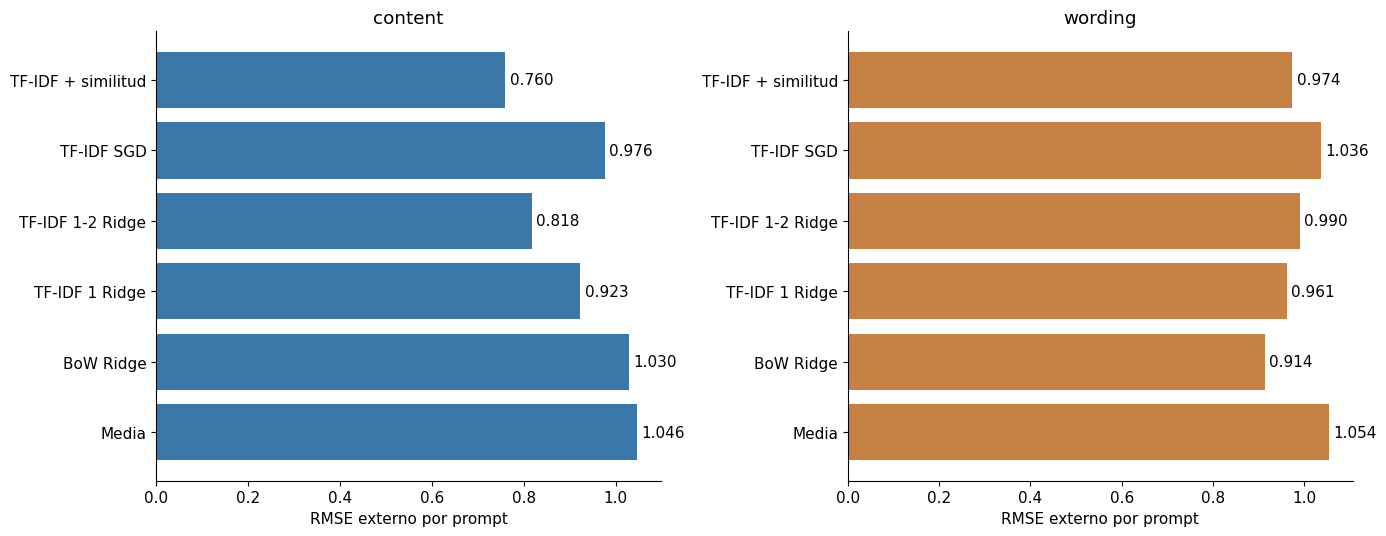

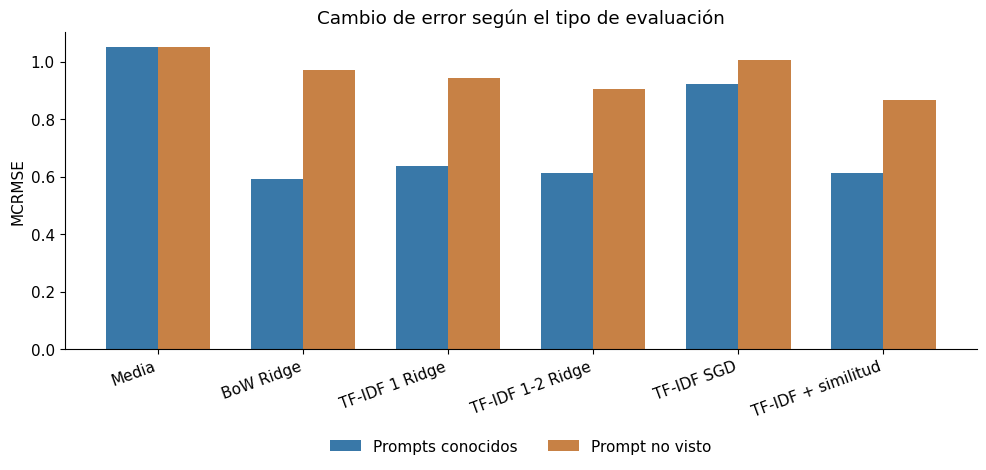

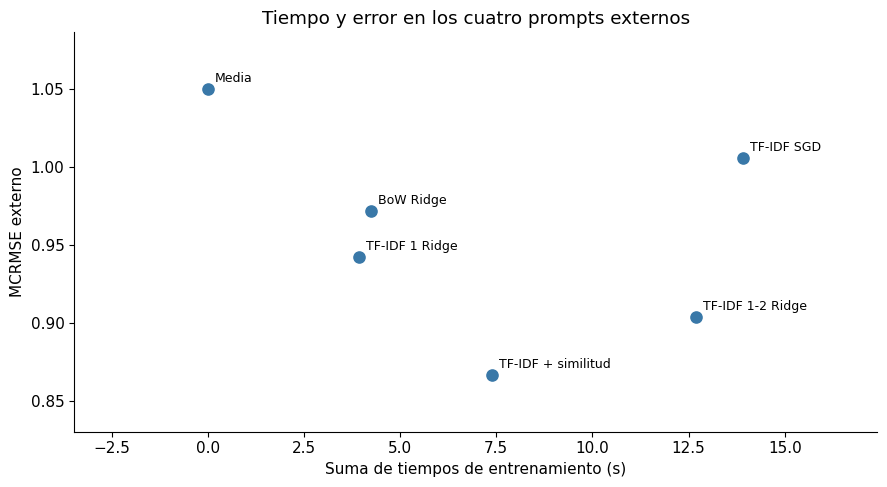

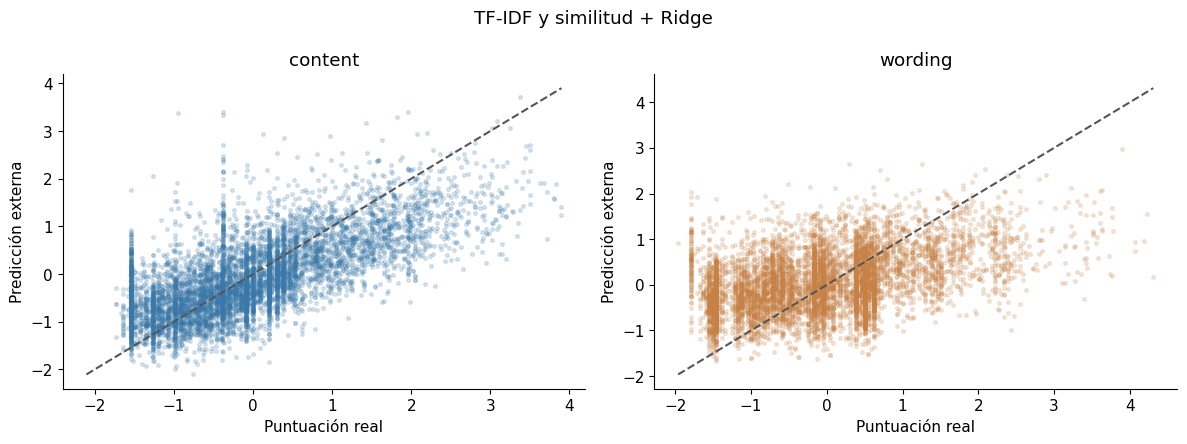

,student_id,prompt_id,content,wording,pred_content,error_abs_content,pred_wording,error_abs_wording,error_abs_promedio
6514,e8e7ef9a087a,ebad26,-0.94817,-1.70784,3.38796,4.33613,1.92407,3.63190,3.98402
4365,9acd09053205,3b9047,-0.38227,-1.79549,3.33978,3.72205,2.03284,3.82833,3.77519
1962,46201a866705,ebad26,-0.38227,-1.79549,3.40284,3.78511,1.91958,3.71507,3.75009
5035,b257979693a2,814d6b,3.11238,4.31069,0.41329,2.69909,0.17062,4.14007,3.41958
1385,322304b00bdc,ebad26,-0.38227,-1.79549,2.70046,3.08273,1.77933,3.57482,3.32878


In [8]:
comparison = holdout_results[["modelo", "mcrmse"]].rename(columns={"mcrmse": "mcrmse_prompts_conocidos"}).merge(
    grouped_results[["modelo", "mcrmse"]].rename(columns={"mcrmse": "mcrmse_prompt_no_visto"}), on="modelo")
comparison["aumento_error"] = comparison.mcrmse_prompt_no_visto - comparison.mcrmse_prompts_conocidos
display(comparison.round(5))
comparison.to_csv(TABLES_DIR / "07_tfidf_protocol_comparison.csv", index=False)
by_prompt = fold_results.pivot(index="modelo", columns="prompt_id", values="mcrmse")
paired = by_prompt.sub(by_prompt.loc["BoW binario + Ridge"], axis=1)
paired["prompts_con_menor_error"] = (paired < 0).sum(axis=1)
paired["diferencia_promedio"] = paired[by_prompt.columns].mean(axis=1)
display(paired.round(5))
paired.to_csv(TABLES_DIR / "07_tfidf_paired_vs_bow.csv", index_label="modelo")
fig, axes = plt.subplots(1, 2, figsize=[14, 5.5])
plot = grouped_results.set_index("modelo").loc[MODEL_ORDER]
short_names = ["Media", "BoW Ridge", "TF-IDF 1 Ridge", "TF-IDF 1-2 Ridge", "TF-IDF SGD", "TF-IDF + similitud"]
for ax, target in zip(axes, TARGETS):
    ax.barh(short_names, plot[f"rmse_{target}"], color=COLORS[target])
    ax.set(title=target, xlabel="RMSE externo por prompt")
    for i, value in enumerate(plot[f"rmse_{target}"]):
        ax.text(value + 0.01, i, f"{value:.3f}", va="center")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "07_tfidf_model_rmse.png", dpi=150, bbox_inches="tight")
plt.show()
fig, ax = plt.subplots(figsize=[10, 5])
positions = np.arange(len(MODEL_ORDER))
plot_protocols = comparison.set_index("modelo").loc[MODEL_ORDER]
ax.bar(positions - 0.18, plot_protocols.mcrmse_prompts_conocidos, width=0.36,
       color=COLORS["content"], label="Prompts conocidos")
ax.bar(positions + 0.18, plot_protocols.mcrmse_prompt_no_visto, width=0.36,
       color=COLORS["wording"], label="Prompt no visto")
ax.set_xticks(positions, short_names, rotation=20, ha="right")
ax.set(title="Cambio de error según el tipo de evaluación", ylabel="MCRMSE")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.24), ncol=2, frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "07_tfidf_protocol_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
fig, ax = plt.subplots(figsize=[9, 5])
for i, row in plot.reset_index().iterrows():
    ax.scatter(row.tiempo_entrenamiento_s, row.mcrmse, s=65, color=COLORS["content"])
    ax.annotate(short_names[i], (row.tiempo_entrenamiento_s, row.mcrmse),
                xytext=(5, 5), textcoords="offset points", fontsize=9)
ax.set(title="Tiempo y error en los cuatro prompts externos", xlabel="Suma de tiempos de entrenamiento (s)",
       ylabel="MCRMSE externo")
ax.margins(x=0.25, y=0.20)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "07_tfidf_time_vs_error.png", dpi=150, bbox_inches="tight")
plt.show()
best_tfidf_name = grouped_results.loc[grouped_results.modelo.str.startswith("TF-IDF")].iloc[0].modelo
best_oof = grouped_predictions[best_tfidf_name]
fig, axes = plt.subplots(1, 2, figsize=[12, 4.5])
for j, (ax, target) in enumerate(zip(axes, TARGETS)):
    ax.scatter(y[:, j], best_oof[:, j], s=7, alpha=0.18, color=COLORS[target])
    limits = [min(y[:, j].min(), best_oof[:, j].min()), max(y[:, j].max(), best_oof[:, j].max())]
    ax.plot(limits, limits, linestyle="--", color="#555555")
    ax.set(title=target, xlabel="Puntuación real", ylabel="Predicción externa")
fig.suptitle(best_tfidf_name)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "07_tfidf_prediction_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()
errors = data[["student_id", "prompt_id", *TARGETS]].copy()
for j, target in enumerate(TARGETS):
    errors[f"pred_{target}"] = best_oof[:, j]
    errors[f"error_abs_{target}"] = np.abs(y[:, j] - best_oof[:, j])
errors["error_abs_promedio"] = errors[["error_abs_content", "error_abs_wording"]].mean(axis=1)
errors.nlargest(15, "error_abs_promedio").to_csv(TABLES_DIR / "07_tfidf_largest_errors.csv", index=False)
display(errors.nlargest(5, "error_abs_promedio").round(5))

### Interpretación de los errores y límites

El modelo TF-IDF y similitud + Ridge pasó de MCRMSE de 0.61303 en prompts conocidos a 0.86709 en prompts no vistos. Se observó una pérdida de desempeño al cambiar de tema. Las predicciones tendieron a concentrarse en la zona central y a subestimar varios casos con puntuaciones altas. El vocabulario aprendido no representa las palabras nuevas y la similitud léxica no reconoce todas las paráfrasis. Los casos de mayor error se conservaron para facilitar una revisión posterior por student_id y prompt_id.

## 9. Entrenamiento final e interpretación

Se seleccionó el modelo TF-IDF con menor MCRMSE externo entre los candidatos evaluados. La comparación externa orienta esta decisión y no equivale a una prueba adicional independiente. Para entrenar el modelo de uso se seleccionaron sus parámetros con validación agrupada sobre los cuatro prompts y se ajustó la configuración elegida con todos los resúmenes.

Se guardó el Pipeline completo para aplicar el mismo vocabulario, IDF y preprocesamiento a entradas nuevas. Los coeficientes permiten revisar asociaciones del modelo; no indican que una palabra cause una mejor puntuación.

In [9]:
final_splits = list(GroupKFold(n_splits=4).split(X, y, groups))
final_model, final_search_seconds = select_model(best_tfidf_name, indices, final_splits, "ajuste_final", "todos")
start = perf_counter()
final_model.fit(X, y)
final_fit_seconds = perf_counter() - start
final_model.set_params(memory=None)
joblib.dump(final_model, PROCESSED_DIR / "07_tfidf_model.joblib", compress=3)
reloaded = joblib.load(PROCESSED_DIR / "07_tfidf_model.joblib")
np.testing.assert_allclose(final_model.predict(X.iloc[:4]), reloaded.predict(X.iloc[:4]))
feature_names = final_model.named_steps["features"].get_feature_names_out()
regressor = final_model.named_steps["model"]
coefficients = np.vstack([model.coef_ for model in regressor.estimators_]) if hasattr(regressor, "estimators_") else regressor.coef_
coefficient_results = coefficient_table(feature_names, coefficients, top_n=10)
coefficient_results.to_csv(TABLES_DIR / "07_tfidf_coefficients.csv", index=False)
display(coefficient_results.round(5))
final_parameters = parameter_rows[-1]
metadata = {"modelo": best_tfidf_name, "parametros": json.loads(final_parameters["parametros"]),
    "filas_entrenamiento": len(data), "objetivos": TARGETS,
    "vocabulario": len(final_model.named_steps["features"].vectorizer_.vocabulary_),
    "ngram_range": list(final_model.named_steps["features"].ngram_range),
    "max_df": 0.98, "max_features": None, "sublinear_tf": True, "smooth_idf": True, "norm": "l2",
    "idf_corpus": "resúmenes de entrenamiento", "tokenizacion": "src.tokenization.tokenize_text",
    "incluye_similitud": final_model.named_steps["features"].include_similarity,
    "tiempo_busqueda_final_s": final_search_seconds, "tiempo_entrenamiento_final_s": final_fit_seconds,
    "python": platform.python_version(), "scikit_learn": sklearn.__version__,
    "plataforma": platform.platform(), "procesador": platform.processor(),
    "validacion": "Leave-One-Prompt-Out externo y GroupKFold interno",
    "archivo_modelo": "data/processed/07_tfidf_model.joblib"}
(PROCESSED_DIR / "07_tfidf_model_metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
(TABLES_DIR / "07_tfidf_model_metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
pd.DataFrame(search_rows).to_csv(TABLES_DIR / "07_tfidf_parameter_search.csv", index=False)
pd.DataFrame(parameter_rows).to_csv(TABLES_DIR / "07_tfidf_selected_parameters.csv", index=False)
display(pd.DataFrame([predict_scores(reloaded, X.iloc[0].text, X.iloc[0].prompt_text)]))

,objetivo,token,coeficiente,dirección
0,content,the,-4.22437,negativa
1,content,it,-1.06945,negativa
2,content,isis egyptians,-0.64725,negativa
3,content,imitate actions,-0.63795,negativa
4,content,3 elements,-0.58284,negativa
5,content,cent also,-0.54558,negativa
6,content,different classes,-0.53940,negativa
7,content,in this,-0.49526,negativa
8,content,were different,-0.48917,negativa
9,content,and those,-0.48707,negativa


,content,wording
0,-0.19463,0.205956


## 10. Verificación y límites del análisis

Se verificó que cada resumen recibiera una predicción externa, que las métricas fueran finitas y que el modelo guardado conservara las predicciones. Se conservó el texto original y se mantuvieron las dos variables objetivo por separado.

La similitud descriptiva y los términos de mayor peso se calcularon con el corpus completo para explorar los datos. Los modelos externos utilizaron representaciones ajustadas dentro del entrenamiento. La evaluación no permite afirmar que TF-IDF detecte plagio o que una palabra específica cause un cambio de puntuación.

In [10]:
assert np.isfinite(holdout_results.select_dtypes(include="number")).all().all()
assert np.isfinite(grouped_results.select_dtypes(include="number")).all().all()
assert all(prediction.shape == y.shape and np.isfinite(prediction).all()
           for prediction in grouped_predictions.values())
assert (similarity >= 0).all() and (similarity <= 1).all()
assert np.all(external_membership == 1)
assert matrix.shape[1] > 0
assert (PROCESSED_DIR / "07_tfidf_model.joblib").is_file()
required_outputs = [TABLES_DIR / "07_tfidf_holdout_results.csv",
                    TABLES_DIR / "07_tfidf_grouped_results.csv",
                    TABLES_DIR / "07_tfidf_selected_parameters.csv",
                    FIGURES_DIR / "07_tfidf_model_rmse.png",
                    FIGURES_DIR / "07_tfidf_protocol_comparison.png",
                    FIGURES_DIR / "07_tfidf_prediction_vs_actual.png"]
assert all(path.is_file() and path.stat().st_size > 0 for path in required_outputs)
assert Path(cache_directory.name).resolve().is_relative_to(Path(tempfile.gettempdir()).resolve())
cache_directory.cleanup()
print("Se verificaron las particiones, las predicciones, el modelo guardado y los resultados exportados.")

Se verificaron las particiones, las predicciones, el modelo guardado y los resultados exportados.


## Cierre

El mejor modelo léxico, TF-IDF con similitud al texto fuente, llega a un MCRMSE cercano a 0.87 con prompts no vistos:
mejor que BoW, pero todavía lejos de lo que logran los mismos modelos con prompts conocidos. El problema de fondo es
que las palabras están atadas al tema de cada texto. Para generalizar a textos nuevos hacen falta representaciones
que no dependan del tema: medidas del resumen en sí, como su largo, su diversidad o cuánto copia, y representaciones
del significado.